<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/03_validation_split_save.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 Validation, Split and Save
Input: furniture_v2 from Drive <br>
Output: furniture_v2_split (train/val/test) and dataset info files

In [2]:
# connect Drive and restore v2
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np, matplotlib.pyplot as plt, json, shutil
from pathlib import Path

DRIVE = "/content/drive/MyDrive/DSGP"
!unzip -q -o {DRIVE}/furniture_v2.zip -d /content
final = pd.read_csv(f"{DRIVE}/furniture_v2_manifest.csv")
v1 = pd.read_csv(f"{DRIVE}/furniture_v1_manifest.csv")
print(len(final), "images in v2")

Mounted at /content/drive
3501 images in v2


In [3]:
# check every class against the rules: min 150 images and at least 30 room crops
summary = final.pivot_table(index="cls", columns="source", values="path", aggfunc="count", fill_value=0)
summary["total"] = summary.sum(axis=1)
summary["room_crops"] = final[final["room_crop"]].groupby("cls").size().reindex(summary.index, fill_value=0)
summary["min_150"] = summary["total"] >= 150
summary["room_30"] = summary["room_crops"] >= 30
summary.sort_values("total")

source,agc,ceylon_furniture,mit_indoor,open_images_v7,total,room_crops,min_150,room_30
cls,,,,,,,,
side_table,0,50,50,0,100,50,False,True
tv_stand,27,97,0,0,124,0,False,False
console_table,19,113,0,0,132,0,False,False
dressing_table,0,137,0,0,137,0,False,False
table,0,0,170,0,170,170,True,True
desk,0,18,11,150,179,161,True,True
coffee_table,0,22,18,150,190,168,True,True
nightstand,0,0,48,150,198,198,True,True
dresser,0,0,51,149,200,200,True,True


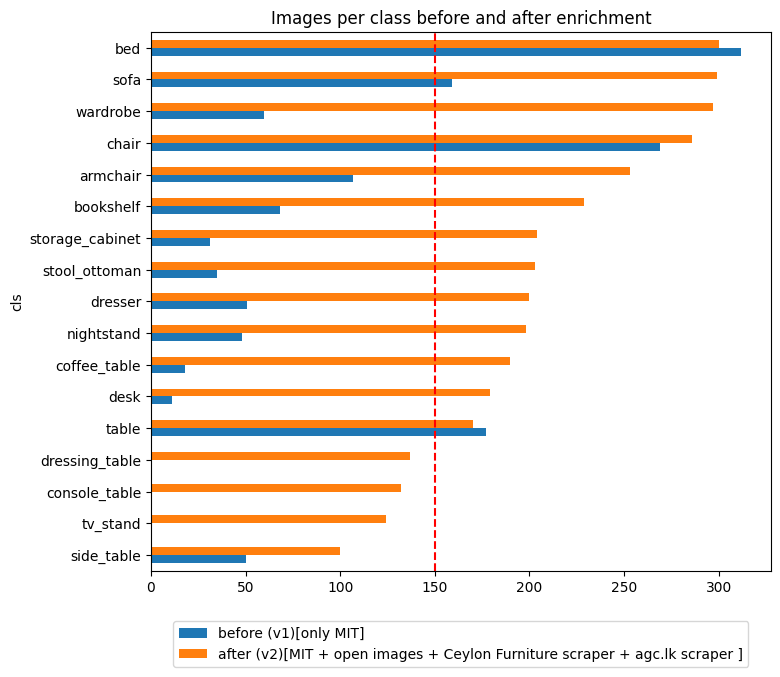

In [4]:
# before vs after: MIT only (v1) against the enriched dataset (v2)
cmp = pd.DataFrame({"before (v1)[only MIT]": v1["cls"].value_counts(),
                    "after (v2)[MIT + open images + Ceylon Furniture scraper + agc.lk scraper ]": final["cls"].value_counts()}).fillna(0)
cmp.sort_values("after (v2)[MIT + open images + Ceylon Furniture scraper + agc.lk scraper ]").plot(kind="barh", figsize=(8, 7))
plt.axvline(150, ls="--", color="red")
plt.title("Images per class before and after enrichment")
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
plt.show()

In [5]:
# assign whole groups (one photo or one product) to a split; test uses room crops only
rng = np.random.default_rng(42)
groups = final.groupby("group_id")["room_crop"].first()

def pick(is_room):
    r = rng.random()
    if is_room:
        return "test" if r < 0.30 else "val" if r < 0.45 else "train"
    return "val" if r < 0.15 else "train"

split_of = {g: pick(is_room) for g, is_room in groups.items()}
final["split"] = final["group_id"].map(split_of)
final.groupby(["cls", "split"]).size().unstack(fill_value=0)

split,test,train,val
cls,,,
armchair,41,179,33
bed,92,156,52
bookshelf,70,111,48
chair,88,161,37
coffee_table,56,111,23
console_table,0,111,21
desk,47,109,23
dresser,66,102,32
dressing_table,0,119,18


In [6]:
# save train/val/test folders, the final manifest and the info files to Drive
SPLIT = Path("/content/furniture_v2_split")
shutil.rmtree(SPLIT, ignore_errors=True)
for r in final.itertuples():
    d = SPLIT / r.split / r.cls
    d.mkdir(parents=True, exist_ok=True)
    shutil.copy(r.path, d / Path(r.path).name)
!rm -f {DRIVE}/furniture_v2_split.zip
!cd /content && zip -q -r {DRIVE}/furniture_v2_split.zip furniture_v2_split

final.to_csv(f"{DRIVE}/furniture_v2_final_manifest.csv", index=False)
json.dump(sorted(final["cls"].unique()), open(f"{DRIVE}/classes.json", "w"), indent=2)
json.dump({"mit_indoor": json.load(open(f"{DRIVE}/mit_label_map.json")),
           "open_images_v7": json.load(open(f"{DRIVE}/oi_map.json")),
           "ceylon_furniture": json.load(open(f"{DRIVE}/ceylon_map.json")),
           "agc": json.load(open(f"{DRIVE}/agc_map.json"))},
          open(f"{DRIVE}/label_map.json", "w"), indent=2)
pd.DataFrame([
    ("mit_indoor", "MIT Indoor Scenes (Quattoni & Torralba, 2009)", "Research/educational use; not redistributed"),
    ("open_images_v7", "Open Images V7 (Google)", "Images listed as CC BY 2.0, annotations CC BY 4.0"),
    ("ceylon_furniture", "ceylonfurniture.lk product images", "Retailer copyright; robots.txt allows crawling; coursework use only, not redistributed"),
     ("agc", "agc.lk product images", "Retailer copyright; robots.txt allows crawling; coursework use only, not redistributed"),
], columns=["source", "description", "licence_or_terms"]).to_csv(f"{DRIVE}/sources.csv", index=False)
print("saved")

saved
